# Part B — Off-Market Prediction

Reproducible walkthrough of the delivered code, measured validation results, and final predictions. Run the pipeline from the repository root first; this notebook does not retrain expensive models automatically. See `README.md` for setup. Hidden-test sale prices are unavailable.


In [1]:
from pathlib import Path
import os, sys, json
root = Path.cwd()
if root.name == "part_b":
    root = root.parent
assert (root / "part_b" / "run.py").is_file(), "Open this notebook from the project or part_b directory"
sys.path.insert(0, str(root))
os.environ.setdefault("MPLCONFIGDIR", "/tmp/part_b_matplotlib")
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
outputs = root / "part_b" / "outputs"


## 1. Verify the inputs and permitted features

The feature boundary excludes list price, target, post-sale fields, AVM and ID. Sale dates are used to define temporal folds only. The property and location data are synthetic.


In [2]:
from part_b.run import load_data
from part_b.features import make_features
train, test = load_data(root / "data")
print(f"Training: {len(train):,}; off-market test: {len(test):,}")
X = make_features(train.head(5))
print(f"Engineered features: {X.shape[1]}")
print(X.columns.tolist())
display(X.head())


Training: 150,000; off-market test: 3,974
Engineered features: 56
['house_type_name', 'house_style', 'municipality', 'community', 'community_type', 'bedrooms', 'washrooms', 'parking_total', 'garage', 'lot_front', 'lot_depth', 'latitude', 'longitude', 'square_feet', 'area_range_width', 'area_is_range', 'area_missing', 'log_square_feet', 'lot_front_missing', 'lot_depth_missing', 'lot_area', 'log_lot_area', 'lot_to_house_area', 'bedrooms_per_1000sqft', 'washrooms_per_1000sqft', 'parking_total_per_1000sqft', 'bath_per_bedroom', 'latitude_longitude', 'listing_months_since_2021', 'listing_year', 'listing_month', 'listing_month_sin', 'listing_month_cos', 'text_renovated', 'text_move_in_ready', 'text_updated_finishes', 'text_needs_work', 'text_original_finishes', 'text_as_is', 'text_luxury', 'text_premium_finishes', 'text_finished_basement', 'text_separate_entrance', 'text_outdoor_space', 'text_views', 'text_waterfront', 'text_natural_light', 'text_amenities', 'text_transit', 'text_parks_schoo

,house_type_name,house_style,municipality,community,community_type,bedrooms,washrooms,parking_total,garage,lot_front,lot_depth,latitude,longitude,square_feet,area_range_width,area_is_range,area_missing,log_square_feet,lot_front_missing,lot_depth_missing,lot_area,log_lot_area,lot_to_house_area,bedrooms_per_1000sqft,washrooms_per_1000sqft,parking_total_per_1000sqft,bath_per_bedroom,latitude_longitude,listing_months_since_2021,listing_year,listing_month,listing_month_sin,listing_month_cos,text_renovated,text_move_in_ready,text_updated_finishes,text_needs_work,text_original_finishes,text_as_is,text_luxury,text_premium_finishes,text_finished_basement,text_separate_entrance,text_outdoor_space,text_views,text_waterfront,text_natural_light,text_amenities,text_transit,text_parks_schools,text_storage,text_parking,text_rental_investment,text_open_layout,text_quiet_privacy,text_word_count
0,Condo Apt,Apartment,Toronto,Sumacpark,Sumacpark | Condo Apt,1.0,1.0,0.0,0.0,NaN,NaN,43.602039,-79.261185,622.0,0.0,0.0,0.0,6.434546,1.0,1.0,NaN,NaN,NaN,1.607717,1.607717,0.000000,1.0,-3455.949219,-0.098563,2020.0,12.0,-2.449294e-16,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,51.0
1,Condo Apt,Apartment,Toronto,Hickorymills,Hickorymills | Condo Apt,2.0,1.0,0.0,0.0,NaN,NaN,43.695389,-79.510864,649.0,0.0,0.0,0.0,6.476973,1.0,1.0,NaN,NaN,NaN,3.081664,1.540832,0.000000,0.5,-3474.258057,-0.197125,2020.0,12.0,-2.449294e-16,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,1.0,1.0,0.0,1.0,89.0
2,Condo Apt,Apartment,North York,Hazelmills,Hazelmills | Condo Apt,2.0,1.0,1.0,0.0,NaN,NaN,43.740513,-79.386215,999.5,199.0,1.0,0.0,6.908255,1.0,1.0,NaN,NaN,NaN,2.001000,1.000500,1.000500,0.5,-3472.393799,-0.328542,2020.0,12.0,-2.449294e-16,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,47.0
3,Condo Apt,Apartment,Scarborough,Sumacbank,Sumacbank | Condo Apt,1.0,1.0,1.0,0.0,NaN,NaN,43.643776,-79.470177,876.0,0.0,0.0,0.0,6.776507,1.0,1.0,NaN,NaN,NaN,1.141553,1.141553,1.141553,1.0,-3468.378662,-0.427105,2020.0,12.0,-2.449294e-16,1.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,57.0
4,Condo Apt,Apartment,Toronto,Ashworth,Ashworth | Condo Apt,1.0,1.0,1.0,0.0,NaN,NaN,43.696171,-79.274139,514.0,0.0,0.0,0.0,6.244167,1.0,1.0,NaN,NaN,NaN,1.945525,1.945525,1.945525,1.0,-3463.976318,-0.887064,2020.0,12.0,-2.449294e-16,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,69.0


## 2. Model selection on earlier months only

Tune on October–November 2025. Candidate families include random forest, histogram gradient boosting and CatBoost, together with baseline comparisons and a no-remarks ablation. The configuration is frozen before the final six-month backtest.


In [3]:
selection = json.loads((outputs / "selection.json").read_text())
print("Selected:", selection["selected_model"])
print(json.dumps(selection["selected_config"], indent=2))
display(pd.DataFrame(selection["tuning_metrics"])[["model", "n", "mdape", "mape"]])


Selected: hist_gradient_boosting
{
  "kind": "hgb",
  "max_iter": 350,
  "learning_rate": 0.07,
  "max_leaf_nodes": 31,
  "l2_regularization": 10.0
}


,model,n,mdape,mape
0,hist_gradient_boosting,4117,9.305977,11.709951
1,catboost_d7_rmse,4117,9.538787,12.065394
2,catboost_d7_mae,4117,9.578221,12.031144
3,catboost_d6_rmse,4117,9.941354,12.636538
4,catboost_no_remarks,4117,10.513494,13.354529
5,random_forest,4117,13.283042,16.989606
6,rolling_community_12m,4117,19.017036,23.577208
7,nearest_sales_10,4117,21.591654,28.883911
8,global_median,4117,35.478288,43.241961


## 3. Untouched-period walk-forward validation

Each December 2025–May 2026 fold trains on sales before the held-out month. Metrics pool 10,069 held-out homes, not monthly averages. This follows the official sale-month protocol and is not a strict per-home listing-time simulation. MdAPE and MAPE are percentage errors, not accuracy percentages.


In [4]:
summary = json.loads((outputs / "metrics_summary.json").read_text())
display(pd.DataFrame(summary["validation_metrics"])[["model", "n", "mdape", "mape", "median_signed_error"]])
monthly = pd.DataFrame(summary["monthly_metrics"])
display(monthly.loc[monthly.model == selection["selected_model"]])


,model,n,mdape,mape,median_signed_error
0,hist_gradient_boosting,10069,9.078818,11.598733,0.492651
1,rolling_community_12m,10069,17.888139,22.246594,2.559445
2,nearest_sales_10,10069,20.842836,27.429720,8.071435
3,global_median,10069,38.459888,46.676210,6.630178


,model,month,n,mdape,mape,median_signed_error,within_10_pct,within_20_pct
6,hist_gradient_boosting,2025-12,1238,9.572023,11.863437,3.857237,51.857835,84.087237
7,hist_gradient_boosting,2026-01,1058,8.850164,11.855904,1.259093,55.103970,82.797732
8,hist_gradient_boosting,2026-02,1442,9.136039,11.407731,-1.094079,53.536755,84.396671
9,hist_gradient_boosting,2026-03,1816,8.750437,11.344415,0.064476,55.341410,84.526432
10,hist_gradient_boosting,2026-04,2224,9.004795,11.307442,0.541442,54.361511,84.577338
11,hist_gradient_boosting,2026-05,2291,9.318990,11.941511,-0.127623,52.771715,82.540375


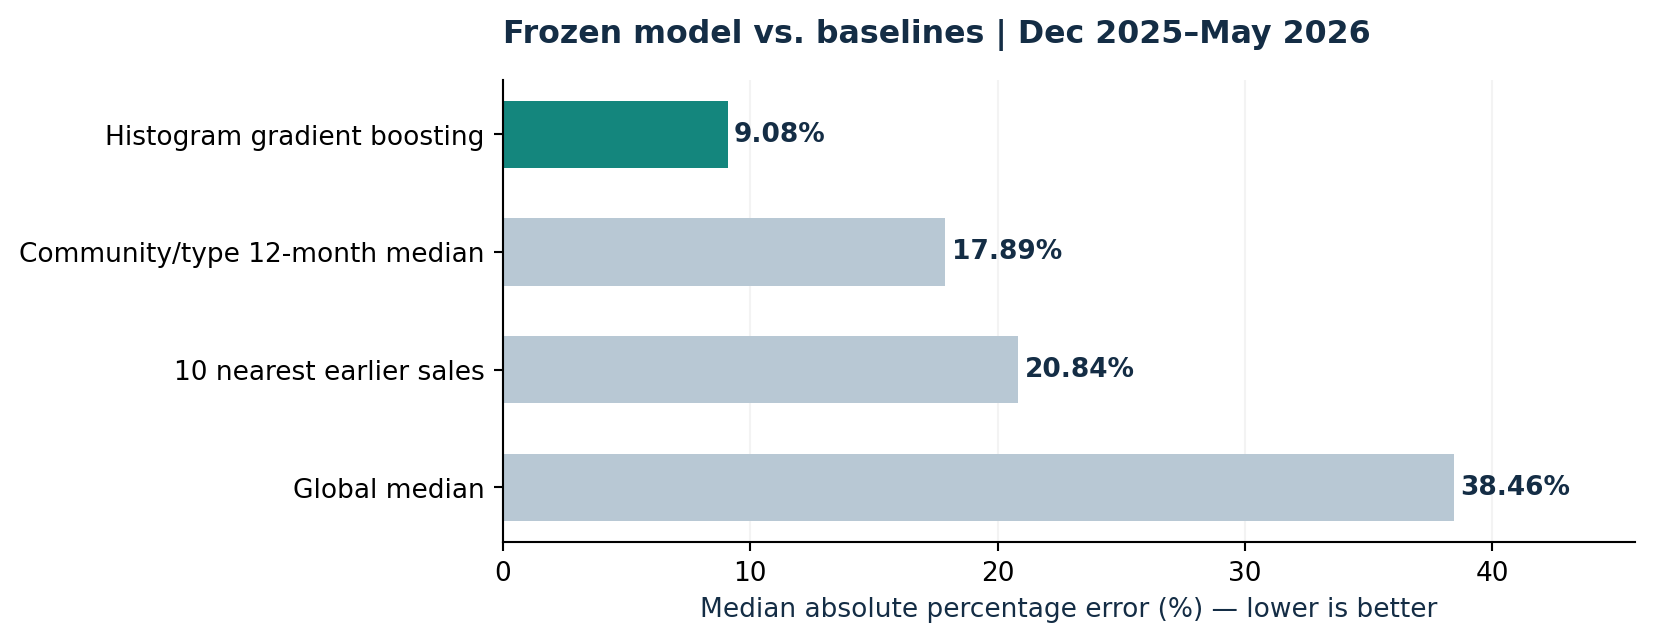

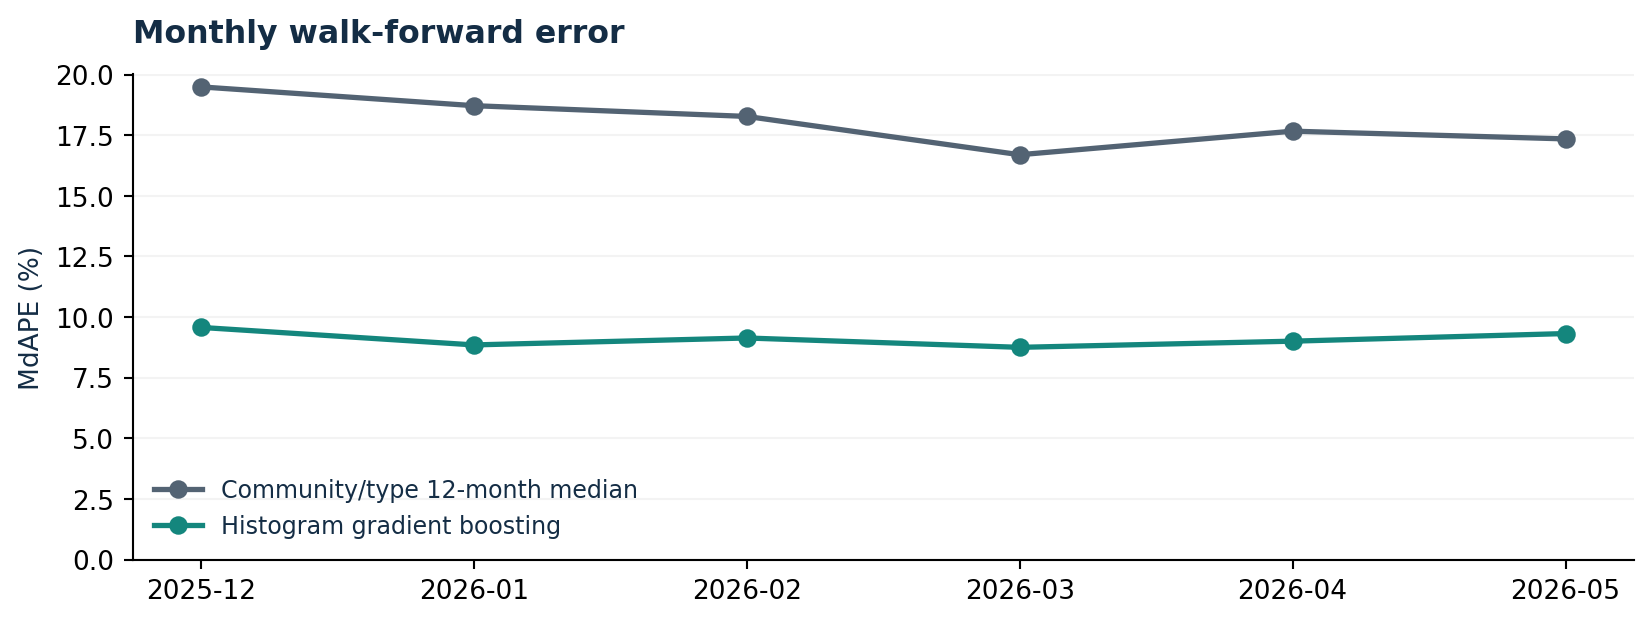

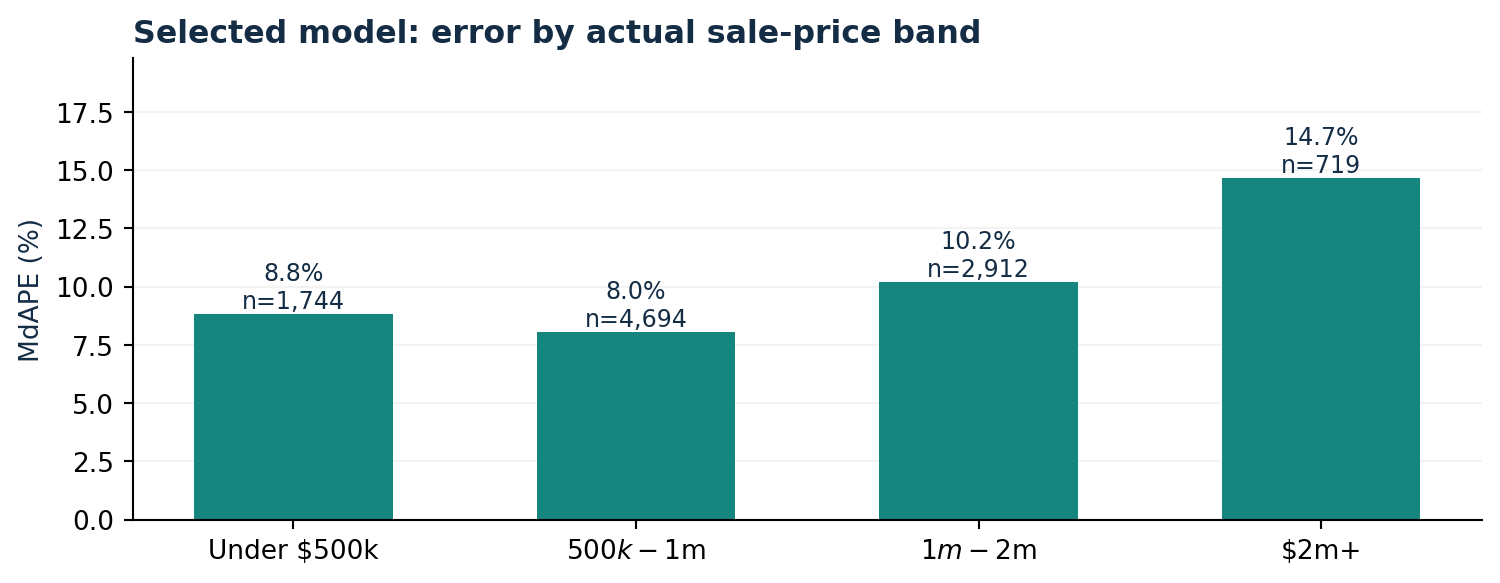

In [5]:
for name in ["validation_comparison.png", "monthly_walk_forward.png", "error_by_price_band.png"]:
    path = root / "part_b" / "figures" / name
    if path.exists():
        display(Image(filename=str(path)))


## 4. Inspect errors and limitations

Use these results with Member D. Luxury and rare-property estimates can be less reliable. Home-level bootstrap intervals do not cover future market-regime shifts. Predictive feature importance is not a causal effect.


In [6]:
groups = pd.read_csv(outputs / "error_groups.csv")
display(groups[groups.group_by.isin(["house_type_name", "price_band"])])
print(summary["selected_95ci"]["note"])


500 iid home resamples; descriptive only, understates shared temporal/location uncertainty.


,group_by,group,n,mdape,mape,median_signed_error,within_10_pct,within_20_pct
0,house_type_name,Co-Op Apt,48,12.019574,19.572530,0.969155,43.750000,64.583333
1,house_type_name,Condo Apt,4843,8.540395,11.038198,1.601676,56.555854,85.773281
2,house_type_name,Condo Townhouse,616,7.746909,9.680182,1.312547,60.551948,90.422078
3,house_type_name,Detached,3123,10.157684,12.731315,-0.154612,49.407621,79.827089
4,house_type_name,Freehold Townhouse,405,8.552123,11.181318,-2.261132,55.555556,83.703704
5,house_type_name,Semi-Detached,1034,9.966253,11.739692,-3.170924,50.193424,83.849130
6,price_band,Under $500k,1744,8.828513,11.705389,7.751106,54.873853,83.256881
7,price_band,$500k-$1m,4694,8.049304,10.316928,0.724341,59.139327,88.005965
8,price_band,$1m-$2m,2912,10.203216,12.250863,-3.728861,49.141484,82.108516
9,price_band,$2m+,719,14.677135,17.067135,-9.565302,35.605007,64.951321


## 5. Load the trained model and reproduce test predictions

Only load trusted joblib files. The provided artifact was refitted on all supplied training sales using the frozen selected configuration.


In [7]:
import joblib
from part_b.run import fingerprint, check_submission
metadata = json.loads((outputs / "models" / "model_metadata.json").read_text())
assert metadata["fingerprint"] == fingerprint(train), "Saved model provenance mismatch"
model = joblib.load(outputs / "models" / "off_market_model.joblib")
submission_path = root / "submissions" / "submission_off_market.csv"
submission = pd.read_csv(submission_path)
check_submission(submission_path, test.ml_num)
reproduced = np.round(model.predict(test.head(10))).astype("int64")
assert np.array_equal(reproduced, submission.predicted_price.head(10).to_numpy())
display(submission.head(10))
print("First ten saved predictions reproduced exactly.")


20:33:13 Submission check PASS: exact schema, complete unique IDs, positive finite prices
First ten saved predictions reproduced exactly.


,ml_num,predicted_price
0,SYN-0011818,491909
1,SYN-0117584,1071228
2,SYN-0065643,594355
3,SYN-0031502,496309
4,SYN-0003276,2362271
5,SYN-0041404,933996
6,SYN-0095694,916697
7,SYN-0037091,486755
8,SYN-0071472,600593
9,SYN-0134428,501019


## 6. Rerun or integrate with the team

From the repository root:
```bash
.venv/bin/python -m part_b all
.venv/bin/python -m part_b.make_deliverables
.venv/bin/python -m part_b check
```
For the official starter, use `part_b.integration.make_off_market_model()` inside the off-market branch and refit it on each fold’s past sales. Keep Part C separate. The team must still combine its report, video and both submission files.
